### Objectives for PCA
#### PCA analysis of ODE simulations: Take simulation outputs and perform PCA.
#### Comparison of PCA distance and intermitotic time: Calculate complete distance for a cell cycle and compare to the times.
#### Vector analysis of stochastic output

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
from scipy.signal import find_peaks
import pandas as pd
from pathlib import Path
import re
import sys
from sklearn.decomposition import PCA

### Files are loaded from the abbreviated ODE stiffness sweep (changing AKT and FAK input) into a dataframe

In [5]:
filenames = sorted(glob.glob(os.getcwd() + "/../Data/ODE_shortened_outputs/*.csv"))

In [6]:
prot_tmp = pd.read_csv(filenames[0], sep=",").drop(columns='Unnamed: 0')
upper_range = round(len(prot_tmp)*0.01,2)
time = np.linspace(0,upper_range-0.01,len(prot_tmp))
#time = np.arange(0,upper_range,0.01).tolist()
prot_tmp.insert(0,'Time',time)
prot_tmp

,Time,skp2,p21,pp21,cdh1,myc,cycD,cycD-p21,Rb,pRb,E2F,E2F-Rb,cycE,cycE-p21,cycA,cycA-p21,cycB,cycB-p21,cdc20
0,0.00,0.062686,0.12838,0.033440,0.022245,0.64583,0.19188,0.050024,0.50889,0.31501,0.019592,0.52863,0.008182,0.003061,0.081822,0.10661,0.68786,0.017137,0.92234
1,0.01,0.062715,0.12844,0.033494,0.022299,0.64583,0.19189,0.050119,0.50890,0.31496,0.019595,0.52868,0.008212,0.003070,0.081083,0.10640,0.68703,0.017166,0.92234
2,0.02,0.062744,0.12849,0.033547,0.022354,0.64583,0.19189,0.050214,0.50891,0.31491,0.019599,0.52874,0.008242,0.003080,0.080350,0.10618,0.68620,0.017194,0.92234
3,0.03,0.062773,0.12855,0.033601,0.022408,0.64583,0.19189,0.050309,0.50892,0.31487,0.019602,0.52879,0.008272,0.003089,0.079623,0.10596,0.68537,0.017223,0.92233
4,0.04,0.062802,0.12860,0.033654,0.022463,0.64583,0.19189,0.050404,0.50892,0.31483,0.019606,0.52885,0.008302,0.003098,0.078901,0.10574,0.68454,0.017251,0.92232
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4564,45.64,0.062530,0.12803,0.033153,0.021955,0.64583,0.19188,0.049507,0.50877,0.31525,0.019576,0.52833,0.008025,0.003013,0.085897,0.10776,0.69224,0.016982,0.92231
4565,45.65,0.062560,0.12810,0.033207,0.022009,0.64583,0.19188,0.049603,0.50879,0.31518,0.019579,0.52838,0.008054,0.003022,0.085126,0.10755,0.69143,0.017011,0.92232
4566,45.66,0.062589,0.12817,0.033260,0.022063,0.64583,0.19188,0.049700,0.50882,0.31512,0.019582,0.52844,0.008083,0.003031,0.084361,0.10734,0.69062,0.017040,0.92233
4567,45.67,0.062618,0.12823,0.033313,0.022116,0.64583,0.19188,0.049796,0.50884,0.31507,0.019585,0.52849,0.008112,0.003040,0.083602,0.10713,0.68980,0.017069,0.92234


### Example plot: Cdc20 Dynamics

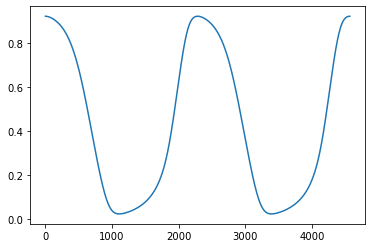

In [7]:
plt.plot(prot_tmp.cdc20)

In [8]:
# What indices represent a full period?
period_ind = prot_tmp[prot_tmp['cdc20']==prot_tmp['cdc20'].iloc[0]].index.values

# The time between the first data point and half the total time is a period:
period_ind

array([   0,    1,    2, 2282, 2283, 2284, 2285, 2286, 2287, 4567, 4568])

# PCA Analysis on one Dataset

In [9]:
# choose number of components and define pca
pca = PCA(n_components = 2)

# use the pca on the data (without the time column)
principalComponents = pca.fit_transform(prot_tmp.iloc[:,1:])

# add results to a dataframe
principal = pd.DataFrame(data = principalComponents, columns = ['principal component 1', 'principal component 2'])
principal

,principal component 1,principal component 2
0,0.920147,-0.084058
1,0.920081,-0.083172
2,0.920015,-0.082287
3,0.919937,-0.081409
4,0.919856,-0.080530
...,...,...
4564,0.920428,-0.088850
4565,0.920393,-0.087953
4566,0.920357,-0.087059
4567,0.920307,-0.086165


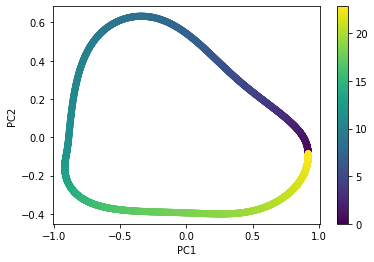

In [10]:
# Scatterplot of the PCA results, color corresponds to time

# Only one period of time is shown
period = round(len(principal)/2)

fig = plt.scatter(principal.iloc[0:period, 0], principal.iloc[0:period, 1], c=prot_tmp['Time'].iloc[0:period])
plt.colorbar(fig)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

# PCA on all Data

In [11]:
# Put all DMSO and ERL data in separate dataframes

data_DMSO = pd.DataFrame()
data_ERL = pd.DataFrame()

for i in range(0,len(filenames)):
    if "dmso" in filenames[i]:
        prot_tmp = pd.read_csv(filenames[i], sep=",").drop(columns='Unnamed: 0')
        upper_range = round(len(prot_tmp)*0.01,2)
        time = np.linspace(0,upper_range-0.01,len(prot_tmp))
        prot_tmp.insert(0,'Time',time)
    
        if data_DMSO.empty:
            data_DMSO = prot_tmp
        else:
            data_DMSO = pd.concat([data_DMSO, prot_tmp], axis=0)
    else:
        prot_tmp = pd.read_csv(filenames[i], sep=",").drop(columns='Unnamed: 0')
        upper_range = round(len(prot_tmp)*0.01,2)
        time = np.linspace(0,upper_range-0.01,len(prot_tmp))
        prot_tmp.insert(0,'Time',time)
    
        if data_ERL.empty:
            data_ERL = prot_tmp
        else:
            data_ERL = pd.concat([data_ERL, prot_tmp], axis=0)

In [12]:
# All data together
data = pd.concat([data_DMSO, data_ERL], axis=0)
data

,Time,skp2,p21,pp21,cdh1,myc,cycD,cycD-p21,Rb,pRb,E2F,E2F-Rb,cycE,cycE-p21,cycA,cycA-p21,cycB,cycB-p21,cdc20
0,0.00,0.062686,0.128380,0.033440,0.022245,0.64583,0.19188,0.050024,0.50889,0.31501,0.019592,0.52863,0.008182,0.003061,0.081822,0.106610,0.68786,0.017137,0.92234
1,0.01,0.062715,0.128440,0.033494,0.022299,0.64583,0.19189,0.050119,0.50890,0.31496,0.019595,0.52868,0.008212,0.003070,0.081083,0.106400,0.68703,0.017166,0.92234
2,0.02,0.062744,0.128490,0.033547,0.022354,0.64583,0.19189,0.050214,0.50891,0.31491,0.019599,0.52874,0.008242,0.003080,0.080350,0.106180,0.68620,0.017194,0.92234
3,0.03,0.062773,0.128550,0.033601,0.022408,0.64583,0.19189,0.050309,0.50892,0.31487,0.019602,0.52879,0.008272,0.003089,0.079623,0.105960,0.68537,0.017223,0.92233
4,0.04,0.062802,0.128600,0.033654,0.022463,0.64583,0.19189,0.050404,0.50892,0.31483,0.019606,0.52885,0.008302,0.003098,0.078901,0.105740,0.68454,0.017251,0.92232
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5486,54.86,0.087279,0.046367,0.028665,0.023845,0.51769,0.17027,0.018701,0.69016,0.14027,0.013048,0.55816,0.006293,0.001095,0.070620,0.046589,0.65520,0.006743,0.91416
5487,54.87,0.087320,0.046360,0.028668,0.023908,0.51769,0.17028,0.018721,0.69015,0.14028,0.013050,0.55817,0.006318,0.001095,0.069862,0.046468,0.65436,0.006752,0.91418
5488,54.88,0.087361,0.046353,0.028671,0.023972,0.51769,0.17029,0.018741,0.69015,0.14028,0.013053,0.55819,0.006344,0.001096,0.069109,0.046347,0.65351,0.006761,0.91419
5489,54.89,0.087402,0.046346,0.028674,0.024036,0.51769,0.17029,0.018760,0.69014,0.14029,0.013056,0.55820,0.006369,0.001097,0.068362,0.046225,0.65267,0.006770,0.91420


In [13]:
# use the pca on all the data (without the time column)
principalComponents = pca.fit_transform(data.iloc[:,1:])

# add results to a dataframe
principal = pd.DataFrame(data = principalComponents, columns = ['principal component 1', 'principal component 2'])
principal

,principal component 1,principal component 2
0,-0.797142,-0.451140
1,-0.797199,-0.450533
2,-0.797257,-0.449925
3,-0.797301,-0.449317
4,-0.797343,-0.448709
...,...,...
2168617,-0.961174,-0.389913
2168618,-0.961193,-0.389325
2168619,-0.961217,-0.388727
2168620,-0.961229,-0.388137


### Scatter plot of all data

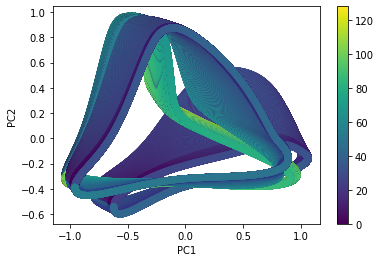

In [27]:
# Scatterplot of all PCA results, color corresponds to time

fig = plt.scatter(principal.iloc[:, 0], principal.iloc[:, 1], c=data['Time'])
plt.colorbar(fig)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.savefig('PCA_fig.png')
plt.show()

### Scatter plot of all DMSO data

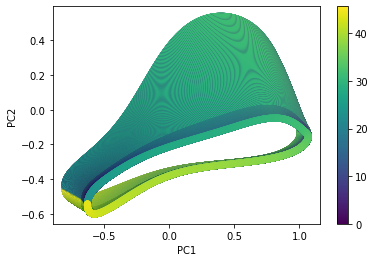

In [26]:
# Color corresponds to time

DMSO_upper = int(len(data_DMSO) - 1)

fig = plt.scatter(principal.iloc[0:DMSO_upper, 0], principal.iloc[0:DMSO_upper, 1], c=data['Time'][0:DMSO_upper])
plt.colorbar(fig)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.savefig('PCA_DMSOfig.png')
plt.show()

### Scatter plot of all ERL data

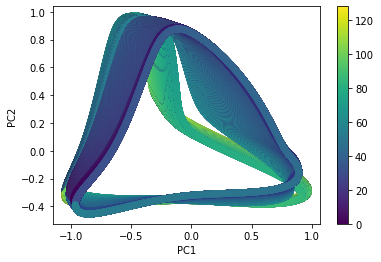

In [25]:
# Scatterplot of ERL PCA results, color corresponds to time
ERL_lower = int(len(data_DMSO))
ERL_upper = int(len(principal) - 1)

fig = plt.scatter(principal.iloc[ERL_lower:ERL_upper, 0], principal.iloc[ERL_lower:ERL_upper, 1], c=data['Time'][ERL_lower:ERL_upper])
plt.colorbar(fig)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.savefig('PCA_ERLfig.png')
plt.show()